<a href="https://colab.research.google.com/github/Arya-rb/Linear-Logistic-Regression-/blob/main/Arya_linear_logistic_regression_scratch.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

In [2]:
data ={
    "Hours_Studied": [1,2,3,4,5,6,7,8,9,10,11,12],
    "Exam_score": [25, 30, 35, 40, 50, 55, 60, 70, 75, 80, 90, 95]
}


In [3]:
df=pd.DataFrame(data)
df

,Hours_Studied,Exam_score
0,1,25
1,2,30
2,3,35
3,4,40
4,5,50
5,6,55
6,7,60
7,8,70
8,9,75
9,10,80


In [4]:
X=df[["Hours_Studied"]]
y=df["Exam_score"]

In [5]:
print(X)


    Hours_Studied
0               1
1               2
2               3
3               4
4               5
5               6
6               7
7               8
8               9
9              10
10             11
11             12


In [6]:
print(y)

0     25
1     30
2     35
3     40
4     50
5     55
6     60
7     70
8     75
9     80
10    90
11    95
Name: Exam_score, dtype: int64


In [7]:
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=42)

In [8]:
print("X_train:",X_train.shape)
print("X_test:",X_test.shape)
print("y_train:",y_train.shape)
print("y_test:",y_test.shape)

X_train: (9, 1)
X_test: (3, 1)
y_train: (9,)
y_test: (3,)


#Linear Regression from scratch

In [9]:
class LinearRegression:
  def fit(self,X,y):
    x=X["Hours_Studied"]
    x_mean=x.mean()
    y_mean=y.mean()
    numerator=((x-x_mean)*(y-y_mean)).sum()
    denominator=((x-x_mean)**2).sum()
    self.slope=numerator/denominator
    self.intercept=y_mean-(self.slope*x_mean)

  def predict(self,X):
    x=X["Hours_Studied"]
    y_pred=self.slope*x+self.intercept
    return y_pred



In [10]:


model = LinearRegression()


model.fit(X_train, y_train)


y_pred = model.predict(X_test)

print("Slope:", model.slope.round(2))
print("Intercept:", model.intercept.round(2))

result = pd.DataFrame({
    "Actual Score": y_test,
    "Predicted Score": y_pred.round(2)
})

print(result)


Slope: 6.62
Intercept: 15.47
    Actual Score  Predicted Score
10            90            88.30
9             80            81.68
0             25            22.09


In [11]:
mae = (y_test - y_pred).abs().mean()

print("Mean Absolute Error:", mae)

Mean Absolute Error: 2.0949720670391123


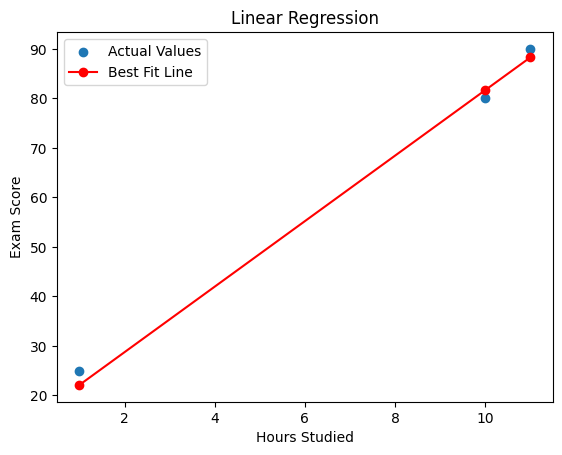

In [12]:
plot_data = pd.DataFrame({
    "Hours_Studied": X_test["Hours_Studied"].values,
    "Actual": y_test.values,
    "Predicted": y_pred
})

plot_data = plot_data.sort_values("Hours_Studied")

plt.scatter(plot_data["Hours_Studied"], plot_data["Actual"],
            label="Actual Values")

plt.plot(plot_data["Hours_Studied"], plot_data["Predicted"],
         color="red", marker="o", label="Best Fit Line")

plt.xlabel("Hours Studied")
plt.ylabel("Exam Score")
plt.title("Linear Regression")
plt.legend()
plt.show()


Logistic Regression from scratch

In [13]:
logistic_data = {
    "Hours_Studied": [1, 2, 3, 4, 5, 6, 7, 8, 9, 10],
    "Result": [0, 0, 0, 0, 0, 1, 1, 1, 1, 1]
}

logistic_df = pd.DataFrame(logistic_data)

logistic_df

,Hours_Studied,Result
0,1,0
1,2,0
2,3,0
3,4,0
4,5,0
5,6,1
6,7,1
7,8,1
8,9,1
9,10,1


In [14]:
X_logistic = logistic_df[["Hours_Studied"]]

y_logistic = logistic_df["Result"]

In [15]:
X_train_logistic, X_test_logistic, y_train_logistic, y_test_logistic = train_test_split(X_logistic, y_logistic, test_size=0.2, random_state=42)

In [16]:
class LogisticRegression:

    def fit(self, X, y):

        x = X["Hours_Studied"]

        fail_mean = x[y == 0].mean()
        pass_mean = x[y == 1].mean()

        threshold = (fail_mean + pass_mean) / 2

        self.m = 1
        self.c = -threshold

    def predict(self, X):

        x = X["Hours_Studied"]

        y_pred = self.m * x + self.c

        probability = 1 / (1 + np.exp(-y_pred))

        prediction = (probability >= 0.5).astype(int)

        return prediction

In [17]:
logistic_model = LogisticRegression()

logistic_model.fit(X_train_logistic, y_train_logistic)

In [18]:
y_pred_logistic = logistic_model.predict(X_test_logistic)

print("Actual Values:")
print(y_test_logistic.values)

print("Predicted Values:")
print(y_pred_logistic)

Actual Values:
[1 0]
Predicted Values:
8    1
1    0
Name: Hours_Studied, dtype: int64


In [19]:
logistic_result = pd.DataFrame({
    "Hours_Studied": X_test_logistic["Hours_Studied"].values,
    "Actual": y_test_logistic.values,
    "Predicted": y_pred_logistic
})

print(logistic_result)

   Hours_Studied  Actual  Predicted
8              9       1          1
1              2       0          0


In [20]:
accuracy_logistic = (y_test_logistic.values == y_pred_logistic).mean() * 100

print("Logistic Regression Accuracy:", accuracy_logistic, "%")

Logistic Regression Accuracy: 100.0 %


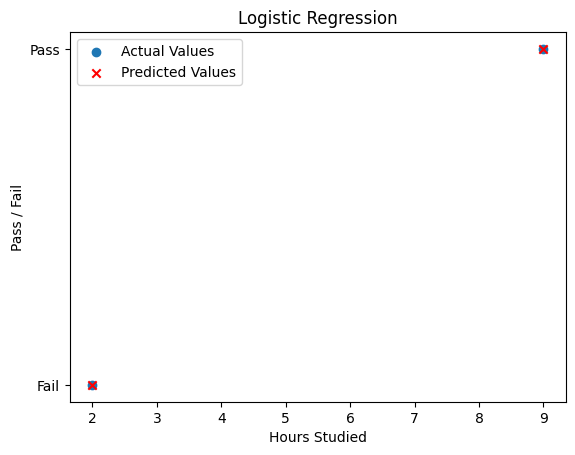

In [21]:
plt.scatter(
    X_test_logistic["Hours_Studied"],
    y_test_logistic,
    label="Actual Values"
)

plt.scatter(
    X_test_logistic["Hours_Studied"],
    y_pred_logistic,
    color="red",
    marker="x",
    label="Predicted Values"
)

plt.xlabel("Hours Studied")
plt.ylabel("Pass / Fail")
plt.title("Logistic Regression")
plt.yticks([0, 1], ["Fail", "Pass"])
plt.legend()
plt.show()